# The cost of portfolio customization
### Personalized model portfolios | Josh Gutierrez

A model allocation is straightforward until an account cannot hold one of its funds,
needs more liquidity, or has a position that needs to stay. How much can the portfolio
change before it stops behaving like the model?

This notebook compares three ways to handle that problem:

1. Redistribute the model weights proportionally, subject to the client's restrictions.
2. Find the feasible portfolio with the lowest estimated tracking risk.
3. Accept a little more tracking risk if it reduces the amount that needs to trade.

The question is about preserving exposures, not forecasting returns. The accounts are
hypothetical. The default data are historical ETF prices; an explicit synthetic mode
is available for an offline walkthrough.

**Scope:** one allocation decision using 2014–2021 data, followed by a 2022–2025 risk
diagnostic. This is not a strategy backtest or a tax-lot execution system.

## 1. Setup

Run `python -m pip install -r requirements.txt` in a terminal, start JupyterLab from
this repository, and select **Restart Kernel and Run All Cells**. Python 3.11 or 3.12
is recommended. The small optimization functions are in `portfolio_engine.py`.

Change `DATA_MODE` to `"synthetic"` if you want to run without a network connection.
Synthetic results are labeled and kept separate from the market-data outputs.

In [1]:
from pathlib import Path
import json
import sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from portfolio_engine import (
    TICKERS, TARGET, CURRENT, ClientRules, example_clients,
    load_market_prices, synthetic_prices, run_study,
    optimize_portfolio, tracking_error, validate_weights,
)

DATA_MODE = "market"          # "market" or "synthetic"; never a silent fallback
REFRESH_DATA = False
TRAIN_END = "2021-12-31"
HOLDOUT_START = "2022-01-01"
EXTRA_TE_BPS = 25.0           # extra annualized tracking risk allowed to save trades
COST_PER_TRADED_DOLLAR_BPS = 5.0
ACCOUNT_VALUE = 1_000_000    # hypothetical account, for the sample trade list only

assert DATA_MODE in {"market", "synthetic"}
OUT = Path("outputs") / DATA_MODE
OUT.mkdir(parents=True, exist_ok=True)
COLORS = {"Proportional": "#8B98A8", "Minimum risk": "#153B59", "Lower turnover": "#168C86"}
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.labelcolor": "#263746", "text.color": "#263746"})

## 2. Data and the model allocation

The eight ETFs provide US large- and small-cap equities, developed and emerging
international equities, intermediate and long Treasuries, gold, and short Treasuries.
**SHY is a short-duration bond ETF, not a risk-free cash balance.**

The target weights and starting account are research assumptions. They were not
optimized against the holdout. The universe is deliberately small and selected with
present-day knowledge, so this is not a survivorship-free investment-selection study.

Yahoo Finance adjusted closes are downloaded through `yfinance`, cached locally,
and hashed. Adjustments incorporate splits and distributions; the source may revise
history. Missing observations cause an error rather than being forward-filled.
Raw downloaded prices are not committed to GitHub.

In [2]:
if DATA_MODE == "market":
    prices, provenance = load_market_prices(refresh=REFRESH_DATA)
else:
    prices, provenance = synthetic_prices(seed=42)

returns = prices.pct_change(fill_method=None).iloc[1:]
assert not returns.isna().any().any()
training = returns.loc[:TRAIN_END]
holdout = returns.loc[HOLDOUT_START:]
assert training.index.max() < holdout.index.min()

display(Markdown(f"**Data source:** {provenance['source']}"))
display(pd.DataFrame({
    "first_date": [training.index.min().date(), holdout.index.min().date()],
    "last_date": [training.index.max().date(), holdout.index.max().date()],
    "observations": [len(training), len(holdout)],
}, index=["Risk estimation", "Untouched later-period risk diagnostic"]))

asset_labels = ["US large cap", "US small cap", "Developed ex-US", "Emerging markets",
                "Intermediate Treasuries", "Long Treasuries", "Gold", "Short Treasuries"]
allocation = pd.DataFrame({"Exposure": asset_labels,
                           "Model %": TARGET * 100, "Starting account %": CURRENT * 100})
display(allocation)

**Data source:** Yahoo Finance via yfinance

,first_date,last_date,observations
Risk estimation,2014-01-03,2021-12-31,2014
Untouched later-period risk diagnostic,2022-01-03,2025-12-31,1003


,Exposure,Model %,Starting account %
SPY,US large cap,30.0,40.0
IWM,US small cap,10.0,15.0
EFA,Developed ex-US,15.0,10.0
EEM,Emerging markets,5.0,5.0
IEF,Intermediate Treasuries,20.0,10.0
TLT,Long Treasuries,5.0,5.0
GLD,Gold,10.0,10.0
SHY,Short Treasuries,5.0,5.0


## 3. What the optimizer is solving

Let $b$ be the model weights, $w$ the client weights, $w_0$ the starting account,
and $\hat\Sigma$ the annualized covariance estimated from the training period.

The minimum-risk portfolio solves:

$$\min_w (w-b)^\top\hat\Sigma(w-b)$$
$$\text{subject to }\quad \mathbf{1}^\top w=1,\qquad l_i\leq w_i\leq u_i.$$

A prohibited fund has a cap of zero. A retained position has a weight floor.
These are allocation constraints at the decision date, not a promise to preserve
share counts indefinitely. There is no shorting or leverage.

The second optimization minimizes $\sum_i|w_i-w_{0,i}|$ while keeping annualized
tracking error no more than **25 basis points above the minimum feasible tracking
error**. This makes the trade-off explicit instead of mixing costs and variance in
an arbitrary weighted objective.

The covariance estimator is Ledoit–Wolf shrinkage. Returns are demeaned inside that
estimator. No expected-return forecast enters either optimization.

The proportional baseline solves $w_i=\operatorname{clip}(k b_i,l_i,u_i)$, choosing
$k$ so weights sum to one. It faces the same constraints as the optimizer.

In [3]:
clients = example_clients()
display(pd.DataFrame([{
    "Client scenario": c.name,
    "Unavailable": ", ".join(c.blocked) or "None",
    "Floors": ", ".join(f"{t}: {v:.0%}" for t, v in c.floors.items()) or "None",
    "Caps": ", ".join(f"{t}: {v:.0%}" for t, v in c.caps.items()) or "None",
} for c in clients]))

results, weights, covariance = run_study(
    training, holdout, clients, allowance_bps=EXTRA_TE_BPS,
    cost_bps=COST_PER_TRADED_DOLLAR_BPS,
)
display(results.round(3))

,Client scenario,Unavailable,Floors,Caps
0,Unrestricted,None,None,None
1,No gold,GLD,None,None
2,No emerging markets,EEM,None,None
3,No long Treasuries,TLT,None,None
4,10% short Treasuries,None,SHY: 10%,None
5,20% short Treasuries,None,SHY: 20%,None
6,Retain 40% US large cap,None,SPY: 40%,None
7,20% US small-cap floor,None,IWM: 20%,None
8,20% position cap,None,None,"SPY: 20%, IWM: 20%, EFA: 20%, EEM: 20%, IEF: 2..."
9,Domestic and liquid,"EFA, EEM",SHY: 15%,None


,client,method,estimated_te_pct,holdout_te_pct,one_way_turnover_pct,gross_traded_pct,estimated_cost_bps,max_weight_pct
0,Unrestricted,Proportional,0.000,0.000,15.000,30.000,1.500,30.000
1,Unrestricted,Minimum risk,0.000,0.000,15.000,30.000,1.500,30.000
2,Unrestricted,Lower turnover,0.250,0.309,12.102,24.204,1.210,32.641
3,No gold,Proportional,1.705,1.759,20.556,41.111,2.056,33.333
4,No gold,Minimum risk,1.291,1.470,26.015,52.029,2.601,28.970
5,No gold,Lower turnover,1.541,1.915,16.415,32.830,1.642,38.139
6,No emerging markets,Proportional,0.723,0.622,17.895,35.789,1.789,31.579
7,No emerging markets,Minimum risk,0.565,0.557,19.163,38.327,1.916,31.396
8,No emerging markets,Lower turnover,0.815,0.961,11.807,23.613,1.181,37.562
9,No long Treasuries,Proportional,0.961,0.867,17.895,35.789,1.789,31.579


## 4. Does a lower estimated tracking risk carry into the holdout?

The optimizer should beat a feasible proportional rule **on the risk estimate it
was designed to minimize**. That is a mathematical check, not evidence of alpha.

The later-period metric is the standard deviation of $R_t(w-b)$, annualized with
252 trading days. It applies the frozen weights to later daily returns as an
exposure diagnostic. It is **not** the realized tracking error of a funded
buy-and-hold account: weights are not drifted, and daily rebalancing costs are not
modeled. Neither net performance nor a trading strategy is claimed.

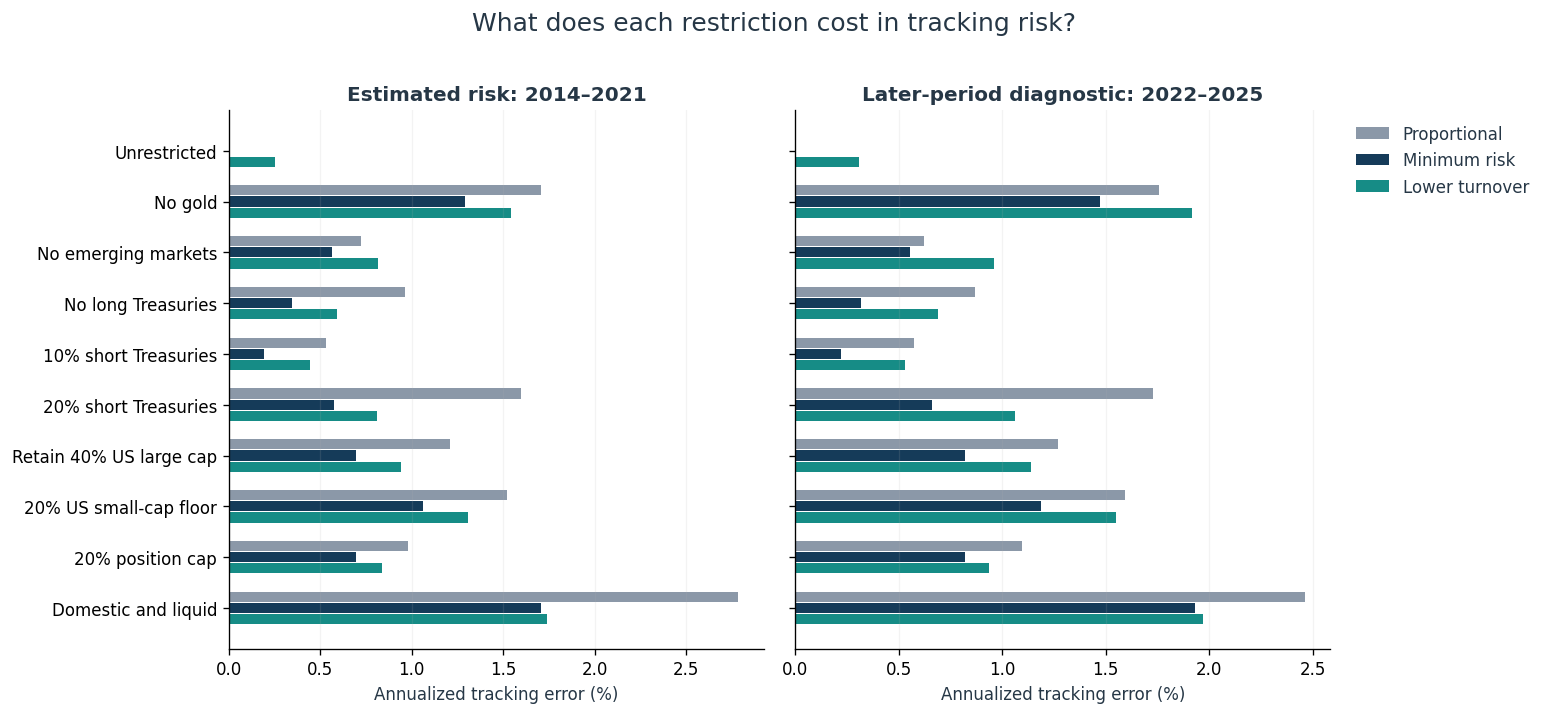

The minimum-risk allocation has lower later-period tracking risk in **9 of 9 constrained scenarios** in this run. This is one historical split, not a significance test or a claim that the ranking will persist.

In [4]:
order = [c.name for c in clients]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), sharey=True)
y = np.arange(len(order))
for ax, metric, title in zip(axes,
        ["estimated_te_pct", "holdout_te_pct"],
        ["Estimated risk: 2014–2021", "Later-period diagnostic: 2022–2025"]):
    table = results.pivot(index="client", columns="method", values=metric).loc[order]
    for offset, method in zip([-.22, 0, .22], COLORS):
        ax.barh(y + offset, table[method], height=.20, label=method, color=COLORS[method])
    ax.set_title(title)
    ax.set_xlabel("Annualized tracking error (%)")
    ax.grid(axis="x", alpha=.15)
axes[0].set_yticks(y, order)
axes[0].invert_yaxis()
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("What does each restriction cost in tracking risk?", fontsize=15, y=1.02)
fig.tight_layout()
fig.savefig(OUT / "tracking_risk.png", dpi=160, bbox_inches="tight")
plt.show()

later = results.pivot(index="client", columns="method", values="holdout_te_pct")
constrained = later.drop(index="Unrestricted")
wins = int((constrained["Minimum risk"] < constrained["Proportional"] - 1e-6).sum())
display(Markdown(
    f"The minimum-risk allocation has lower later-period tracking risk in **{wins} of "
    f"{len(constrained)} constrained scenarios** in this run. This is one historical "
    "split, not a significance test or a claim that the ranking will persist."
))

## 5. How much trading can a small risk allowance avoid?

One-way turnover is half the sum of absolute weight changes. Estimated cost charges
**both buys and sells**, at the stated basis points per dollar traded. For example,
moving 10% of an account from one fund to another trades 20% of account value.

These are one-time transition-cost estimates. They are reported separately and are
not deducted from a wealth path. A funded execution model would also need a cash
budget, share rounding, spreads, taxes, and order timing.

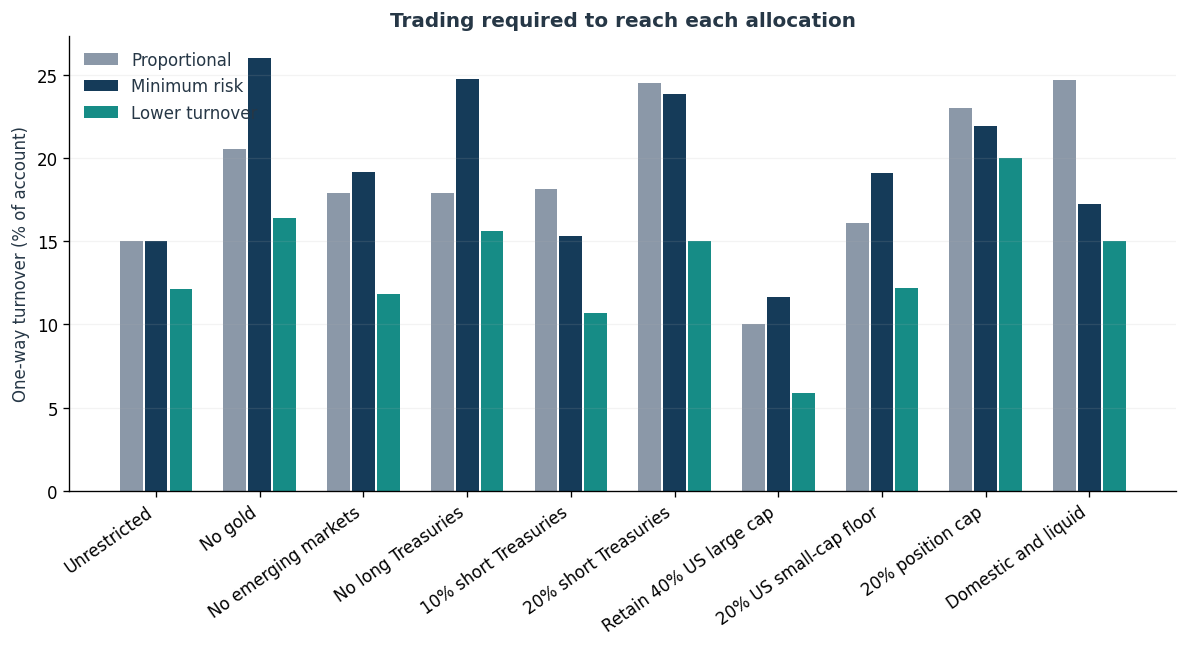

One-time estimated cost (bps of account)  1 bps per traded dollar  \
client                  method                                      
Unrestricted            Proportional                        0.300   
                        Minimum risk                        0.300   
                        Lower turnover                      0.242   
No gold                 Proportional                        0.411   
                        Minimum risk                        0.520   
                        Lower turnover                      0.328   
No emerging markets     Proportional                        0.358   
                        Minimum risk                        0.383   
                        Lower turnover                      0.236   
No long Treasuries      Proportional                        0.358   
                        Minimum risk                        0.495   
                        Lower turnover                      0.312   
10% short Treasuries    Proportional                        0.363   
                        Minimum risk                        0.306   
                        Lower turnover                      0.214   
20% short Treasuries    Proportional                        0.489   
                        Minimum risk                        0.476   
                        Lower turnover                      0.300   
Retain 40% US large cap Proportional                        0.200   
                        Minimum risk                        0.233   
                        Lower turnover                      0.118   
20% US small-cap floor  Proportional                        0.322   
                        Minimum risk                        0.382   
                        Lower turnover                      0.244   
20% position cap        Proportional                        0.460   
                        Minimum risk                        0.439   
                        Lower turnover                      0.400   
Domestic and liquid     Proportional                        0.493   
                        Minimum risk                        0.344   
                        Lower turnover                      0.300   

One-time estimated cost (bps of account)  5 bps per traded dollar  \
client                  method                                      
Unrestricted            Proportional                        1.500   
                        Minimum risk                        1.500   
                        Lower turnover                      1.210   
No gold                 Proportional                        2.056   
                        Minimum risk                        2.601   
                        Lower turnover                      1.642   
No emerging markets     Proportional                        1.789   
                        Minimum risk                        1.916   
                        Lower turnover                      1.181   
No long Treasuries      Proportional                        1.789   
                        Minimum risk                        2.474   
                        Lower turnover                      1.561   
10% short Treasuries    Proportional                        1.816   
                        Minimum risk                        1.532   
                        Lower turnover                      1.068   
20% short Treasuries    Proportional                        2.447   
                        Minimum risk                        2.381   
                        Lower turnover                      1.500   
Retain 40% US large cap Proportional                        1.000   
                        Minimum risk                        1.165   
                        Lower turnover                      0.588   
20% US small-cap floor  Proportional                        1.611   
                        Minimum risk                        1.908   
                        Lower turnover                      1.219 

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
turnover = results.pivot(index="client", columns="method", values="one_way_turnover_pct").loc[order]
x = np.arange(len(order))
for offset, method in zip([-.24, 0, .24], COLORS):
    ax.bar(x + offset, turnover[method], width=.22, label=method, color=COLORS[method])
ax.set_xticks(x, order, rotation=35, ha="right")
ax.set_ylabel("One-way turnover (% of account)")
ax.set_title("Trading required to reach each allocation")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.15)
fig.tight_layout()
fig.savefig(OUT / "turnover.png", dpi=160, bbox_inches="tight")
plt.show()

gross = results.set_index(["client", "method"])["gross_traded_pct"] / 100
cost_sensitivity = pd.DataFrame({f"{c} bps per traded dollar": gross * c for c in [1, 5, 10]})
display(cost_sensitivity.round(3).rename_axis(columns="One-time estimated cost (bps of account)"))

## 6. A customization curve

Instead of deciding that every restriction is harmless or unacceptable, increase
one retained-position floor and measure the resulting minimum tracking risk.
Here the floor is on SPY. Everything else is unchanged.

Because each larger floor shrinks the feasible set, the minimum achievable risk
cannot improve. A material decline would be a bug or a numerical problem.

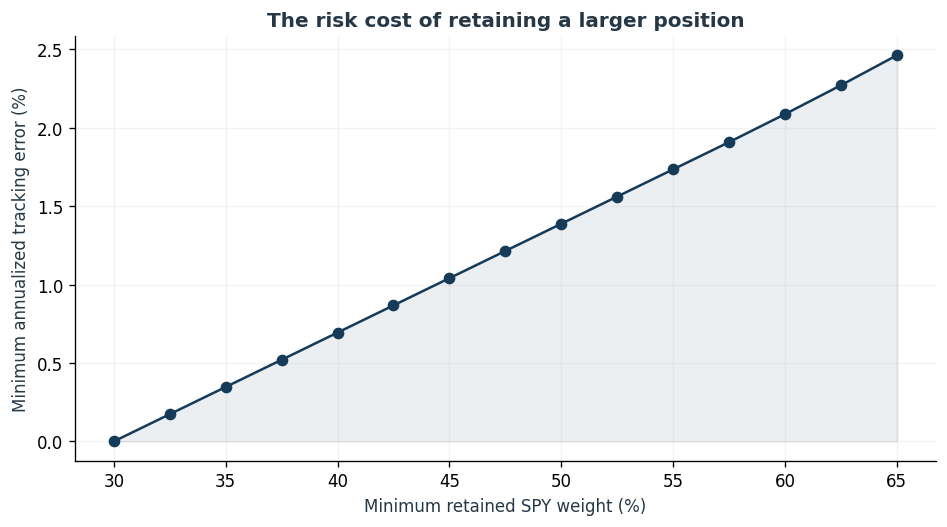

In [6]:
curve_rows = []
for floor in np.linspace(.30, .65, 15):
    rule = ClientRules("US large-cap floor", floors={"SPY": float(floor)})
    w = optimize_portfolio(TARGET, covariance, rule)
    curve_rows.append({"retained_weight_pct": floor * 100,
                       "minimum_te_pct": tracking_error(w, TARGET, covariance) * 100})
curve = pd.DataFrame(curve_rows)
assert (curve.minimum_te_pct.diff().dropna() >= -1e-5).all()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve.retained_weight_pct, curve.minimum_te_pct, "o-", color=COLORS["Minimum risk"])
ax.fill_between(curve.retained_weight_pct, curve.minimum_te_pct, alpha=.08,
                color=COLORS["Minimum risk"])
ax.set(xlabel="Minimum retained SPY weight (%)", ylabel="Minimum annualized tracking error (%)",
       title="The risk cost of retaining a larger position")
ax.grid(alpha=.15)
fig.tight_layout()
fig.savefig(OUT / "customization_curve.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. One account, explained

The sample account cannot use international equity ETFs and needs at least 15% in
short Treasuries. Compare its model weights, current weights, and proposed weights.
The trade list is illustrative, before costs, and not an order file.

In [7]:
client_name = "Domestic and liquid"
proposed = weights.loc[(client_name, "Lower turnover")]
trade_list = pd.DataFrame({"Model %": TARGET * 100, "Current %": CURRENT * 100,
                           "Proposed %": proposed * 100,
                           "Change (percentage points)": (proposed - CURRENT) * 100,
                           "Illustrative trade $": (proposed - CURRENT) * ACCOUNT_VALUE})
trade_list["Action"] = np.where(abs(proposed - CURRENT) < 1e-6, "Hold",
                                 np.where(proposed > CURRENT, "Buy", "Sell"))
display(trade_list.round(2))
display(Markdown(
    "The foreign-equity positions must exit under the account restrictions. "
    "The short-Treasury floor changes the portfolio's risk capacity. The other "
    "positions balance the estimated tracking-risk budget against the starting "
    "holdings. This is covariance-based substitution, not a view that any fund "
    "will outperform."
))
trade_list.to_csv(OUT / "illustrative_trade_list.csv")

,Model %,Current %,Proposed %,Change (percentage points),Illustrative trade $,Action
SPY,30.0,40.0,40.72,0.72,7239.40,Buy
IWM,10.0,15.0,15.61,0.61,6118.48,Buy
EFA,15.0,10.0,0.00,-10.00,-100000.00,Sell
EEM,5.0,5.0,0.00,-5.00,-50000.00,Sell
IEF,20.0,10.0,10.89,0.89,8901.87,Buy
TLT,5.0,5.0,6.13,1.13,11303.50,Buy
GLD,10.0,10.0,11.04,1.04,10423.63,Buy
SHY,5.0,5.0,15.60,10.60,106013.12,Buy


The foreign-equity positions must exit under the account restrictions. The short-Treasury floor changes the portfolio's risk capacity. The other positions balance the estimated tracking-risk budget against the starting holdings. This is covariance-based substitution, not a view that any fund will outperform.

## 8. What happens when the instructions cannot be satisfied?

The engine should reject an impossible account rather than return a portfolio
that looks plausible. In this example every position is capped at 10%, which
cannot sum to 100% across eight assets.

In [8]:
impossible = ClientRules("Impossible account", caps={t: .10 for t in TICKERS})
try:
    optimize_portfolio(TARGET, covariance, impossible)
except ValueError as error:
    print("Expected rejection:", error)
else:
    raise AssertionError("An infeasible account must not return a portfolio")

for client in clients:
    for _, portfolio in weights.loc[client.name].iterrows():
        validate_weights(portfolio, client)
print(f"Validated all {len(weights)} allocations against their client constraints.")

Expected rejection: Infeasible bounds: full investment is impossible
Validated all 30 allocations against their client constraints.


## 9. Results to take away, and what still needs work

The important output is a trade-off, not the name of the solver. A PM can ask:

- Which restrictions create meaningful exposure differences?
- Does accepting a modest tracking-risk increase avoid enough trading to matter?
- How sensitive is that decision to the covariance estimate?
- When should an account be escalated rather than automatically allocated?

**Limits of this version:** one chosen universe and historical split; fixed target
weights; constant transaction-cost assumptions; no taxes, liability matching,
private assets, liquidity stress, or funded execution. SHY is not cash. Weight floors
do not model share-level no-sell restrictions. Historical ETF correlations are not
guaranteed to persist. The later-period calculation is a risk diagnostic, not a
net-return backtest.

**Next research step:** rolling, point-in-time covariance estimates and a holdings-
based transition simulation with explicit cash funding. Only after that would it
make sense to claim realized trading-cost savings or compare net performance.

This is an AI-assisted research prototype. The methods and assumptions are made
explicit so the code, results, and investment interpretation can be reviewed.

In [9]:
results.to_csv(OUT / "scenario_results.csv", index=False)
weights.to_csv(OUT / "portfolio_weights.csv")
curve.to_csv(OUT / "customization_curve.csv", index=False)
summary = {
    "data_mode": DATA_MODE, "data_provenance": provenance,
    "training_end": str(training.index.max().date()),
    "holdout_start": str(holdout.index.min().date()),
    "holdout_end": str(holdout.index.max().date()),
    "training_observations": len(training), "holdout_observations": len(holdout),
    "client_scenarios": len(clients), "allocations": len(weights),
    "extra_te_budget_bps": EXTRA_TE_BPS,
    "cost_bps_per_traded_dollar": COST_PER_TRADED_DOLLAR_BPS,
    "lower_holdout_risk_count": wins, "constrained_scenarios": len(constrained),
    "python": sys.version.split()[0],
    "versions": {n: importlib.metadata.version(n) for n in
                 ["numpy", "pandas", "cvxpy", "scikit-learn", "yfinance"]},
    "interpretation": "Static construction and later-period risk diagnostic; not a funded strategy backtest."
}
(OUT / "run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(f"Saved tables, charts, and the run summary in outputs/{DATA_MODE}/")

Saved tables, charts, and the run summary in outputs/market/


## References

- [CVXPY portfolio optimization example](https://www.cvxgrp.org/cvx_short_course/docs/applications/notebooks/portfolio_optimization.html)
- [Ledoit–Wolf covariance estimator](https://scikit-learn.org/stable/modules/generated/sklearn.covariance.LedoitWolf.html)
- [yfinance documentation and data-use notes](https://ranaroussi.github.io/yfinance/)
- Ledoit, O. and Wolf, M. (2004), *A well-conditioned estimator for large-dimensional covariance matrices*, Journal of Multivariate Analysis, 88(2), 365–411.